# Q2 · Part B (tabular) — Random Forest experiments on **Heart Disease UCI**

> **Before running:** put the heart-disease CSV into `data/q2_heart/` (Kaggle: *Heart Disease UCI* — either `heart.csv` or `heart_disease_uci.csv` works).
> **Run order for Question 2:** `01_Q2_Heart_Disease.ipynb` → `02_Q2_Intel_Images.ipynb` → `03_Q2_Comparative_Analysis.ipynb`

Experiments in this notebook
1. Test accuracy vs number of trees (`n_estimators`) — repeated over several random seeds to also measure **stability**
2. Single Decision Tree vs Random Forest (default parameters): accuracy + training time
3. Detailed comparison Decision Tree vs Random Forest vs SVM (default and tuned, cross-validation, ROC, confusion matrices)

In [1]:
# ---- Project setup: finds the project root automatically ----
import os, sys, json, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

def find_root():
    start = Path(os.environ.get("LAB_ROOT", Path.cwd())).resolve()
    for p in [start, *start.parents]:
        if (p / "requirements.txt").exists() and (p / "src").exists():
            return p
    raise RuntimeError("Project root not found. Open this notebook from inside the Prog_for_AI_Lab folder.")

ROOT = find_root()
sys.path.insert(0, str(ROOT / "src"))
print("Project root:", ROOT)

Project root: C:\Users\hp\Desktop\Prog_for_AI_Lab\Prog_for_AI_Lab


In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, classification_report
from lab_utils import *
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

In [3]:
SEED = 42
TEST_SIZE = 0.20
N_LIST = [1, 10, 50, 100, 200, 300]     # values of n_estimators to try
SWEEP_SEEDS = [0, 1, 2, 3, 4]           # repeat each setting with 5 random seeds (stability)

## 1. Dataset description and exploration

In [4]:
df, X, y, target_col, path = load_heart(ROOT / "data" / "q2_heart")
print("File:", path.name, "| shape:", df.shape, "| target column:", target_col, "(converted to 0 = no disease, 1 = disease)")
display(df.head())
print("\nMissing values per column:"); print(df.isna().sum()[df.isna().sum() > 0].to_string() or "none")
print("\nClass balance:"); print(y.value_counts().rename({0: "no disease", 1: "disease"}).to_string())

File: heart_cleveland_upload.csv | shape: (297, 14) | target column: condition (converted to 0 = no disease, 1 = disease)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,condition
0,69,1,0,160,234,1,2,131,0,0.1,1,1,0,0
1,69,0,0,140,239,0,0,151,0,1.8,0,2,0,0
2,66,0,0,150,226,0,0,114,0,2.6,2,0,0,0
3,65,1,0,138,282,1,2,174,0,1.4,1,1,0,1
4,64,1,0,110,211,0,2,144,1,1.8,1,0,0,0



Missing values per column:
Series([], )

Class balance:
condition
no disease    160
disease       137


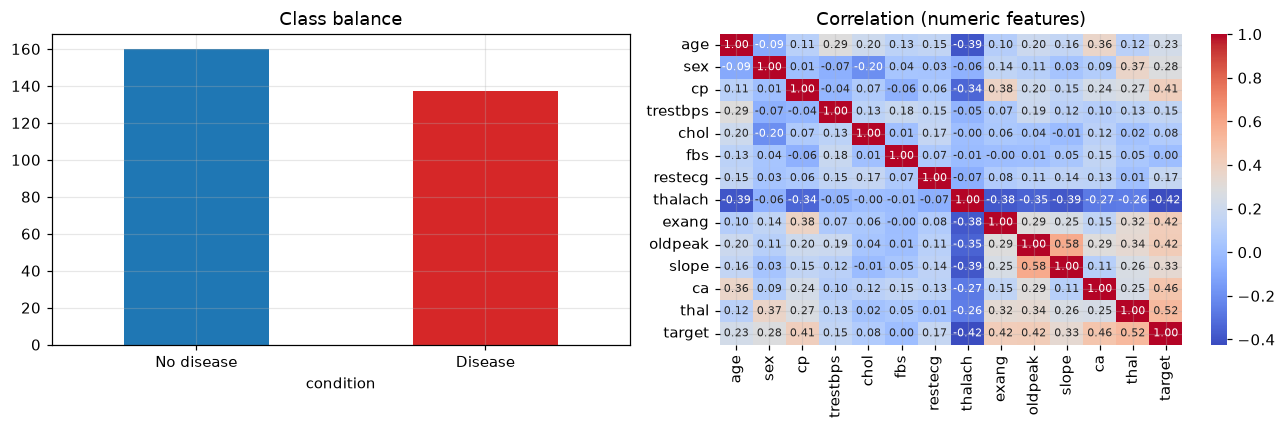

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
y.map({0: "No disease", 1: "Disease"}).value_counts().plot.bar(ax=axes[0], color=["tab:blue", "tab:red"], rot=0)
axes[0].set_title("Class balance")
num = X.select_dtypes(include=[np.number]).copy(); num["target"] = y
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1], annot_kws={"size": 7}); axes[1].set_title("Correlation (numeric features)")
plt.tight_layout(); savefig(fig, "q2", "heart_eda"); plt.show()

## 2. Preprocessing and train/test split
* stratified 80/20 split (keeps the class ratio equal in both parts)
* numeric: median imputation + standardisation · categorical: most-frequent imputation + one-hot encoding
* the preprocessor is **fitted on the training data only** (no leakage)

In [6]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)
prep, num_cols, cat_cols = make_preprocessor(X)
Xtr = prep.fit_transform(X_tr); Xte = prep.transform(X_te)
print("numeric:", num_cols); print("categorical:", cat_cols)
print("train:", Xtr.shape, "test:", Xte.shape)

numeric: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
categorical: []
train: (237, 13) test: (60, 13)


## 3. Experiment 1 — test accuracy vs number of trees

In [7]:
sweep = sweep_n_estimators(Xtr, y_tr.values, Xte, y_te.values, ns=N_LIST, seeds=SWEEP_SEEDS)
summary = summarize_sweep(sweep); display(summary.round(4))

  n_estimators=   1 done
  n_estimators=  10 done
  n_estimators=  50 done
  n_estimators= 100 done
  n_estimators= 200 done
  n_estimators= 300 done


,n_estimators,test_acc_mean,test_acc_std,train_acc_mean,oob_acc_mean,train_time_mean
0,1,0.7433,0.0480,0.8937,NaN,0.0293
1,10,0.8367,0.0594,0.9873,0.7342,0.0496
2,50,0.8467,0.0217,1.0000,0.7747,0.1668
3,100,0.8500,0.0118,1.0000,0.7941,0.3773
4,200,0.8433,0.0091,1.0000,0.8093,0.6631
5,300,0.8467,0.0139,1.0000,0.8034,1.1413


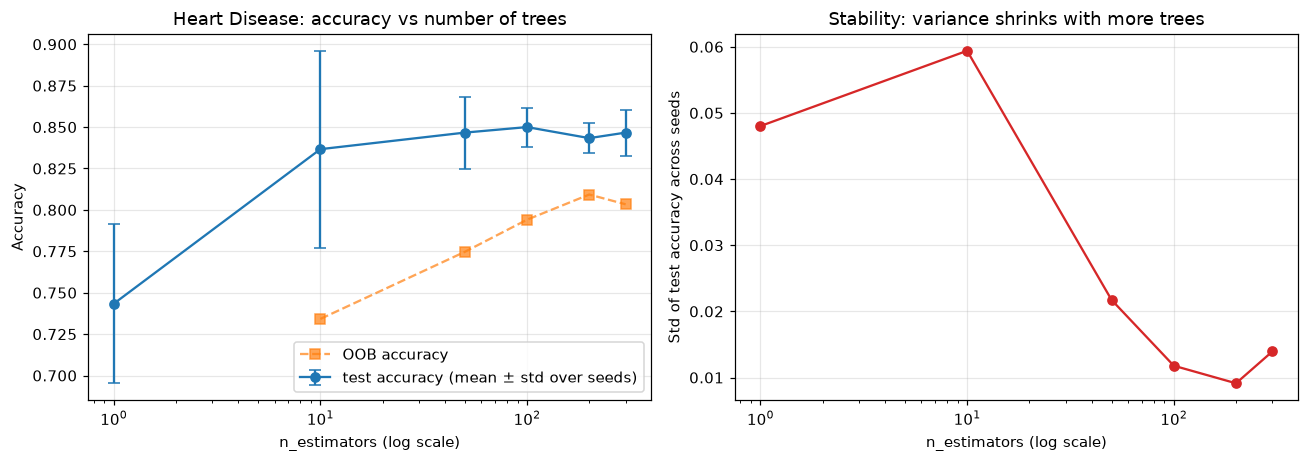

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ax = axes[0]
ax.errorbar(summary.n_estimators, summary.test_acc_mean, yerr=summary.test_acc_std, fmt="o-", capsize=4, label="test accuracy (mean ± std over seeds)")
ax.plot(summary.n_estimators, summary.oob_acc_mean, "s--", alpha=0.7, label="OOB accuracy")
ax.set_xscale("log"); ax.set_xlabel("n_estimators (log scale)"); ax.set_ylabel("Accuracy"); ax.legend(); ax.set_title("Heart Disease: accuracy vs number of trees")
axes[1].plot(summary.n_estimators, summary.test_acc_std, "o-", color="tab:red"); axes[1].set_xscale("log")
axes[1].set_xlabel("n_estimators (log scale)"); axes[1].set_ylabel("Std of test accuracy across seeds"); axes[1].set_title("Stability: variance shrinks with more trees")
plt.tight_layout(); savefig(fig, "q2", "heart_n_estimators"); plt.show()

## 4. Experiment 2 — single Decision Tree vs Random Forest (default parameters)

In [9]:
dt_res, dt_model, dt_pred = evaluate_model(DecisionTreeClassifier(random_state=SEED), Xtr, y_tr.values, Xte, y_te.values, "Decision Tree (default)", n_repeats=10)
rf_res, rf_model, rf_pred = evaluate_model(RandomForestClassifier(random_state=SEED, n_jobs=-1), Xtr, y_tr.values, Xte, y_te.values, "Random Forest (default, 100 trees)", n_repeats=10)
dt_vs_rf = [dt_res, rf_res]
display(pd.DataFrame(dt_vs_rf).round(4))

,model,accuracy,precision,recall,f1,train_time_s,predict_time_s,roc_auc
0,Decision Tree (default),0.7833,0.8000,0.7143,0.7547,0.0028,0.0002,0.7790
1,"Random Forest (default, 100 trees)",0.8833,0.9565,0.7857,0.8627,0.3300,0.0585,0.9448


## 5. Experiment 3 — comparison with SVM and Decision Tree
### 5a. Default hyper-parameters on the test set

In [10]:
svm_res, svm_model, svm_pred = evaluate_model(SVC(random_state=SEED), Xtr, y_tr.values, Xte, y_te.values, "SVM (RBF, default)", n_repeats=10)
comparison = [dt_res, rf_res, svm_res]
display(pd.DataFrame(comparison).round(4))

,model,accuracy,precision,recall,f1,train_time_s,predict_time_s,roc_auc
0,Decision Tree (default),0.7833,0.8000,0.7143,0.7547,0.0028,0.0002,0.7790
1,"Random Forest (default, 100 trees)",0.8833,0.9565,0.7857,0.8627,0.3300,0.0585,0.9448
2,"SVM (RBF, default)",0.9000,1.0000,0.7857,0.8800,0.0059,0.0014,0.9397


### 5b. 5-fold stratified cross-validation (more reliable than a single split)
The full pipeline (preprocessing + model) is cross-validated, so imputation/scaling are learned inside each fold.

In [11]:
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
def pipe(model): return Pipeline([("prep", make_preprocessor(X)[0]), ("clf", model)])
cv = {}
for name, model in [("Decision Tree", DecisionTreeClassifier(random_state=SEED)),
                    ("Random Forest", RandomForestClassifier(random_state=SEED, n_jobs=-1)),
                    ("SVM", SVC(random_state=SEED))]:
    s = cross_val_score(pipe(model), X, y, cv=skf, scoring="accuracy")
    cv[name] = {"mean": float(s.mean()), "std": float(s.std()), "folds": s.tolist()}
    print(f"{name:14s} CV accuracy = {s.mean():.4f} ± {s.std():.4f}")

Decision Tree  CV accuracy = 0.7411 ± 0.0594
Random Forest  CV accuracy = 0.8151 ± 0.0518
SVM            CV accuracy = 0.8254 ± 0.0553


### 5c. Hyper-parameter tuning (GridSearchCV, 5-fold on the training set only)

In [12]:
grids = {
  "Decision Tree": (DecisionTreeClassifier(random_state=SEED), {"max_depth": [2, 3, 4, 5, 6, 8, None], "min_samples_leaf": [1, 3, 5, 10]}),
  "Random Forest": (RandomForestClassifier(random_state=SEED, n_jobs=-1), {"n_estimators": [100, 300], "max_depth": [None, 5, 10], "max_features": ["sqrt", 0.5]}),
  "SVM":           (SVC(random_state=SEED), {"C": [0.1, 1, 10, 100], "gamma": ["scale", 0.01, 0.1], "kernel": ["rbf", "linear"]}),
}
tuned, best_params = [], {}
for name, (model, grid) in grids.items():
    gs = GridSearchCV(model, grid, cv=5, scoring="accuracy", n_jobs=-1).fit(Xtr, y_tr.values)
    r, _, _ = evaluate_model(gs.best_estimator_, Xtr, y_tr.values, Xte, y_te.values, f"{name} (tuned)", n_repeats=3)
    r["cv_best_score"] = float(gs.best_score_); tuned.append(r); best_params[name] = gs.best_params_
    print(name, "->", gs.best_params_)
display(pd.DataFrame(tuned).round(4))

Decision Tree -> {'max_depth': 3, 'min_samples_leaf': 10}
Random Forest -> {'max_depth': None, 'max_features': 'sqrt', 'n_estimators': 100}
SVM -> {'C': 0.1, 'gamma': 0.1, 'kernel': 'rbf'}


,model,accuracy,precision,recall,f1,train_time_s,predict_time_s,roc_auc,cv_best_score
0,Decision Tree (tuned),0.7667,0.7692,0.7143,0.7407,0.0026,0.0006,0.8092,0.7725
1,Random Forest (tuned),0.8833,0.9565,0.7857,0.8627,0.2511,0.0396,0.9448,0.8231
2,SVM (tuned),0.8667,1.0000,0.7143,0.8333,0.0059,0.0024,0.9230,0.8274


### 5d. Confusion matrices and ROC curves (default models)

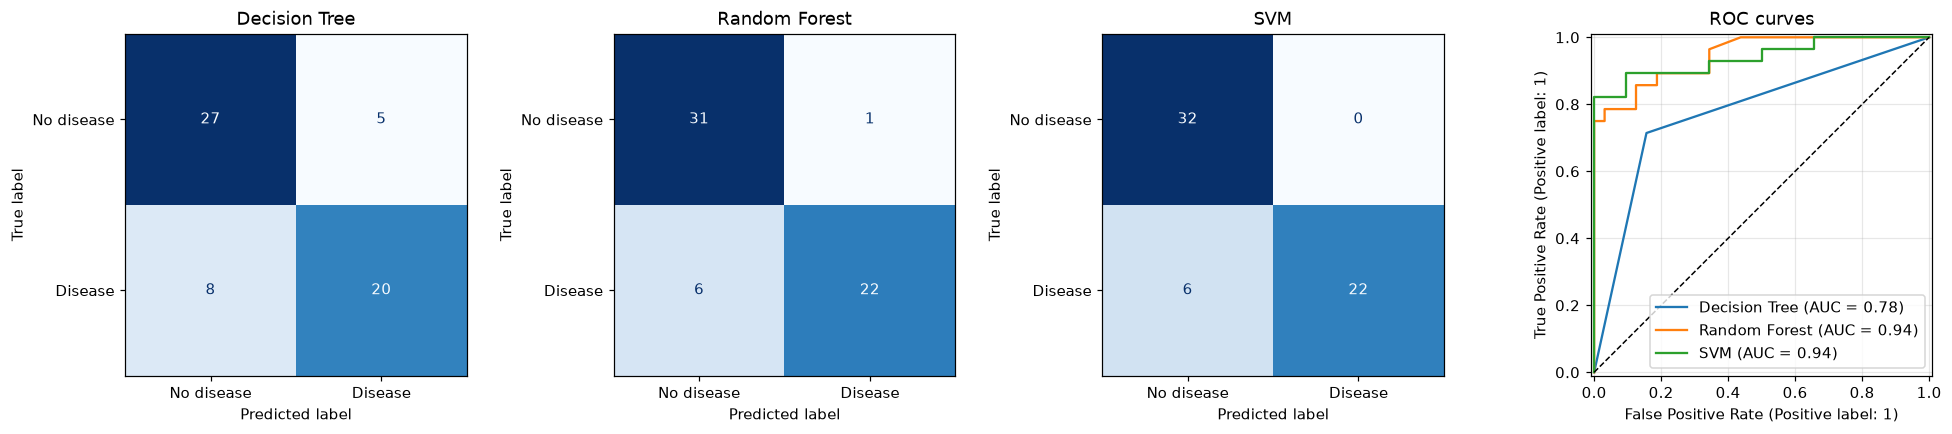

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, pred) in zip(axes[:3], [("Decision Tree", dt_pred), ("Random Forest", rf_pred), ("SVM", svm_pred)]):
    ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=["No disease", "Disease"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name); ax.grid(False)
for name, m in [("Decision Tree", dt_model), ("Random Forest", rf_model), ("SVM", svm_model)]:
    RocCurveDisplay.from_estimator(m, Xte, y_te, ax=axes[3], name=name)
axes[3].plot([0, 1], [0, 1], "k--", lw=1); axes[3].set_title("ROC curves")
plt.tight_layout(); savefig(fig, "q2", "heart_cm_roc"); plt.show()

### 5e. What does the forest consider important?

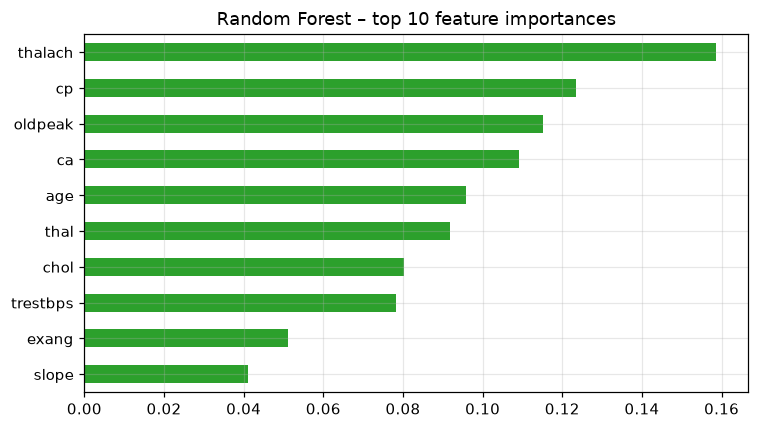

In [14]:
feat_names = prep.get_feature_names_out()
imp = pd.Series(rf_model.feature_importances_, index=[n.split("__")[-1] for n in feat_names]).sort_values(ascending=False).head(10)
fig, ax = plt.subplots(figsize=(7, 4)); imp[::-1].plot.barh(ax=ax, color="tab:green"); ax.set_title("Random Forest – top 10 feature importances")
plt.tight_layout(); savefig(fig, "q2", "heart_feature_importance"); plt.show()

## 6. Save results for the report

In [ ]:
results = {
  "dataset": {"name": "Heart Disease UCI", "file": path.name, "rows": int(len(df)), "n_features": int(X.shape[1]),
              "numeric_features": num_cols, "categorical_features": cat_cols,
              "missing_values": int(df.isna().sum().sum()), "class_balance": {"no_disease": int((y == 0).sum()), "disease": int((y == 1).sum())},
              "n_train": int(len(y_tr)), "n_test": int(len(y_te)), "n_features_after_encoding": int(Xtr.shape[1])},
  "preprocessing": "Stratified 80/20 split; numeric: median imputation + StandardScaler; categorical: most-frequent imputation + one-hot encoding; fitted on training data only.",
  "sweep_raw": sweep.to_dict("records"), "sweep_summary": summary.to_dict("records"),
  "dt_vs_rf": dt_vs_rf, "comparison": comparison, "tuned": tuned, "best_params": best_params, "cv": cv,
  "feature_importance": imp.to_dict(), "seeds": SWEEP_SEEDS, "n_list": N_LIST,
}
save_json(results, ROOT / "results" / "q2" / "heart_results.json")
print("Saved results/q2/heart_results.json ✔")

Saved results/q2/heart_results.json ✔


: 